In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch

In [10]:
# 1. Load the dataset
df = pd.read_csv("iris.csv")

In [11]:
# 2. Extract numeric features
features = df.drop(columns=["Id", "Species"], errors="ignore")

In [12]:
# 3. Scale the features (Highly recommended for Hierarchical Clustering)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

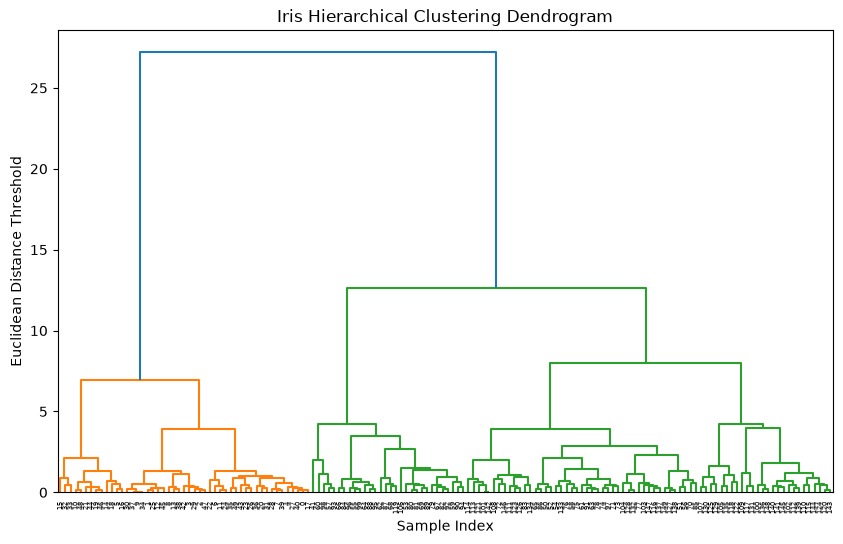

In [13]:
# 4. Generate and Plot the Dendrogram using SciPy
plt.figure(figsize=(10, 6))
plt.title("Iris Hierarchical Clustering Dendrogram")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance Threshold")

# Linkage matrix using Ward's variance minimization method
linkage_matrix = sch.linkage(scaled_features, method="ward")
dendrogram = sch.dendrogram(linkage_matrix)
plt.show()

In [14]:
# 5. Fit the Agglomerative (Hierarchical) model using Scikit-Learn
# Based on the 3 biological species (or structural splits in the dendrogram)
hc = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
df["HC_Cluster"] = hc.fit_predict(scaled_features)

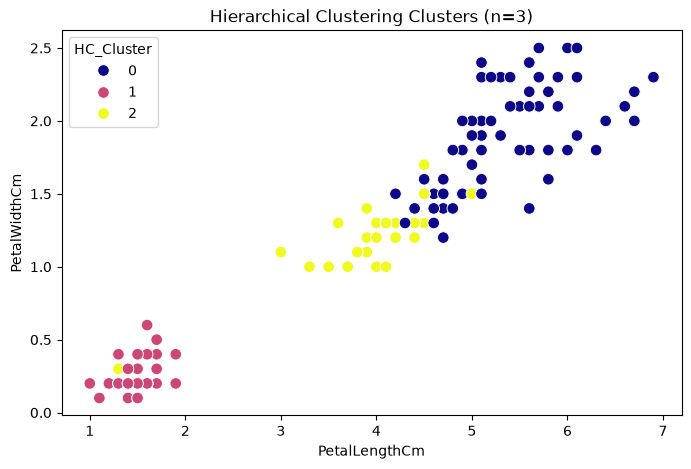

In [15]:
# 6. Visualize the output (Petal Length vs Petal Width)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, 
    x="PetalLengthCm", # Adjust if your CSV column names are lowercase (e.g., 'petal_length')
    y="PetalWidthCm", 
    hue="HC_Cluster", 
    palette="plasma", 
    s=70
)
plt.title("Hierarchical Clustering Clusters (n=3)")
plt.show()